#Data upload

In [ ]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"barathmr10","key":"498fd96d9a25928e15b87aa1a79e832f"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d arjuntejaswi/plant-village

Dataset URL: https://www.kaggle.com/datasets/arjuntejaswi/plant-village
License(s): unknown
100% 329M/329M [00:01<00:00, 178MB/s]



In [ ]:
!unzip plant-village.zip -d dataset

Streaming output truncated to the last 5000 lines.
  inflating: dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/08c033bd-fbc3-445a-88d1-1863070e52ce___YLCV_GCREC 2872.JPG  
  inflating: dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/08dd176c-e9d9-4746-92c3-fa8dc9074347___UF.GRC_YLCV_Lab 03057.JPG  
  inflating: dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/08f78a80-46f5-45a6-937c-4d05d61c08c2___UF.GRC_YLCV_Lab 01895.JPG  
  inflating: dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/0903aa95-6e8a-4abd-a003-126fcd9a5493___YLCV_GCREC 2806.JPG  
  inflating: dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/0911d416-d73d-4c2a-8e45-207a7ceb7c9a___YLCV_GCREC 2773.JPG  
  inflating: dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/09188838-cc89-4925-94c5-d9563c4cb4bf___UF.GRC_YLCV_Lab 02974.JPG  
  inflating: dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/0922e026-b563-438d-b9ed-7476153023ce___YLCV_GCREC 2258.JPG  


In [ ]:
!rm -rf /content/dataset/PlantVillage/Pepper__bell___Bacterial_spot/
!rm -rf /content/dataset/PlantVillage/Pepper__bell___healthy/
!rm -rf /content/dataset/PlantVillage/Tomato__Target_Spot//
!rm -rf /content/dataset/PlantVillage/Tomato__Tomato_mosaic_virus/
!rm -rf /content/dataset/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/
!rm -rf /content/dataset/PlantVillage/Tomato_Bacterial_spot/
!rm -rf /content/dataset/PlantVillage/Tomato_Early_blight/
!rm -rf /content/dataset/PlantVillage/Tomato_healthy/
!rm -rf /content/dataset/PlantVillage/Tomato_Late_blight/
!rm -rf /content/dataset/PlantVillage/Tomato_Leaf_Mold/
!rm -rf /content/dataset/PlantVillage/Tomato_Septoria_leaf_spot/
!rm -rf /content/dataset/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite/

#Data load

In [49]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [50]:
Image_size = 256
Batch_size = 32
Channels = 3
Epochs = 10

In [51]:
#Pipeline to load image into TF.data.dataset for batch and resize
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/dataset/PlantVillage",
    shuffle = True,
    seed=42,
    image_size = (Image_size, Image_size),
    batch_size = Batch_size
)

Found 2152 files belonging to 3 classes.


In [52]:
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

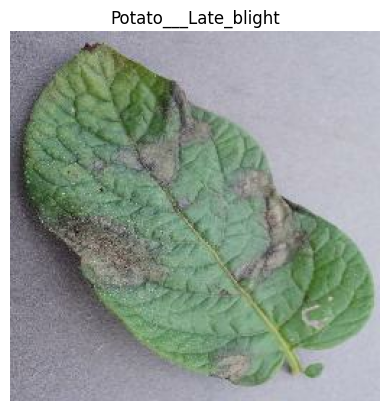

In [53]:
for image_batch, labels_batch in dataset.take(1):
  plt.imshow(image_batch[0].numpy().astype("uint8"))
  plt.title(class_names[labels_batch[0]])
  plt.axis("off")

#Data split

In [54]:
print(len(dataset)*0.8)

54.400000000000006


In [ ]:
# train_ds = dataset.take(54)
# valid_ds = dataset.skip(54)
# test_ds = valid_ds.skip(6)
# valid_ds = valid_ds.take(6)
# print(len(valid_ds))
# print(len(test_ds))
# print(len(train_ds))

6
8
54


In [55]:
def get_train_test_split(ds, train_size = 0.8, test_size = 0.1, shuffle=True, shuffle_size = 10000):

  ds_size = len(ds)

  if shuffle:
    ds = ds.shuffle(shuffle_size, seed = 42)

  train_size = int(ds_size*train_size)
  test_size = int(ds_size*test_size)
  train_ds = ds.take(train_size)
  valid_ds = ds.skip(train_size).take(test_size)
  test_ds = ds.skip(train_size).skip(test_size)
  return train_ds, test_ds, valid_ds


In [56]:
train_ds, test_ds, valid_ds = get_train_test_split(dataset)
print(len(valid_ds))
print(len(test_ds))
print(len(train_ds))

6
8
54


In [57]:
#Optimizing dataset cache = save load data in memory for nextload, shuffle = randomize sample-each batch-varied data
#prefetch = when a batch is train, it parallely load other batch
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
valid_ds = valid_ds.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)

In [58]:
# scaling image between 0-1 and reshaping all the images to 256x256
rescale_resize = tf.keras.Sequential([
    layers.Resizing(Image_size, Image_size),
    layers.Rescaling(1.0/255)
])

In [59]:
# Creating different form of img from a given image for robust prediction
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2)
])

In [62]:
input_shape = (Batch_size, Image_size,Image_size, Channels)
n_class = 3
#creates the model and defines its layers/order
model2 = models.Sequential([
    rescale_resize,
    data_augmentation,
    layers.Conv2D(32,(3,3), activation='relu', input_shape=input_shape),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.MaxPool2D((2,2)),
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.MaxPool2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_class, activation='softmax')
])
model2.build(input_shape=input_shape)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [63]:
model2.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_13 (Sequential)      │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_14 (Sequential)      │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (32, 254, 254, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_48 (MaxPooling2D) │ (32, 127, 127, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (32, 125, 125, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_49 (MaxPooling2D) │ (32, 62, 62, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_50 (Conv2D)              │ (32, 60, 60, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_50 (MaxPooling2D) │ (32, 30, 30, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_51 (Conv2D)              │ (32, 28, 28, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_51 (MaxPooling2D) │ (32, 14, 14, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_52 (Conv2D)              │ (32, 12, 12, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_52 (MaxPooling2D) │ (32, 6, 6, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_53 (Conv2D)              │ (32, 4, 4, 64)         │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_53 (MaxPooling2D) │ (32, 2, 2, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (32, 256)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (32, 64)               │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (32, 3)                │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [64]:
model2.compile(
    optimizer='adam',
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [65]:
history = model2.fit(
    train_ds,
    epochs=Epochs,
    batch_size = Batch_size,
    verbose =1,
    validation_data = valid_ds
)

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 225s 4s/step - accuracy: 0.4935 - loss: 0.8953 - val_accuracy: 0.5990 - val_loss: 0.7630
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 210s 4s/step - accuracy: 0.6649 - loss: 0.7234 - val_accuracy: 0.7708 - val_loss: 0.4622
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 209s 4s/step - accuracy: 0.8116 - loss: 0.4876 - val_accuracy: 0.8802 - val_loss: 0.3982
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 210s 4s/step - accuracy: 0.8668 - loss: 0.3268 - val_accuracy: 0.8438 - val_loss: 0.3978
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 212s 4s/step - accuracy: 0.9296 - loss: 0.1955 - val_accuracy: 0.5625 - val_loss: 1.6156
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 218s 4s/step - accuracy: 0.9131 - loss: 0.2438 - val_accuracy: 0.8177 - val_loss: 0.3939
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 211s 4s/step - accuracy: 0.9173 - loss: 0.1941 - val_accuracy: 0.8802 - val_loss: 0.3320
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 211s 4s/step - accuracy: 0.9583 - loss: 0.1058 - val_accuracy: 0.8906 - v

In [66]:
score = model2.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9805 - loss: 0.0922


In [67]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [68]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

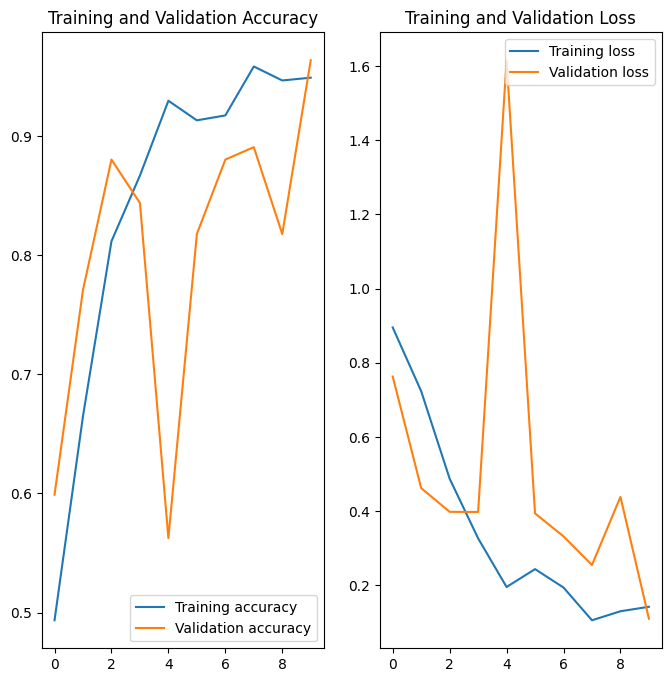

In [70]:
plt.figure(figsize=(8,8))
plt.subplot(1,2,1)
plt.plot(range(Epochs), acc, label='Training accuracy')
plt.plot(range(Epochs), val_acc, label='Validation accuracy')
plt.legend(loc = 'lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1,2,2)
plt.plot(range(Epochs), loss, label='Training loss')
plt.plot(range(Epochs), val_loss, label='Validation loss')
plt.legend(loc = 'upper right')
plt.title('Training and Validation Loss')
plt.show()

Image to predict
Image label = Potato___Early_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
prediction = Potato___Early_blight


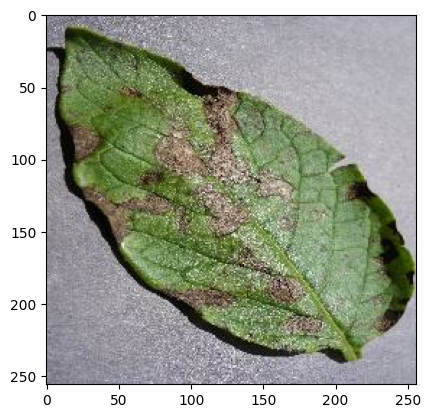

In [78]:
import numpy as np
for image_batch, image_lable in test_ds.take(1):

  first_img = image_batch[0].numpy().astype('uint8')
  first_lbl = image_lable[0].numpy()

  print('Image to predict')
  plt.imshow(first_img)
  print('Image label =', class_names[first_lbl])

  batch_prediction = model2.predict(image_batch)
  predicted_lable = np.argmax(batch_prediction[0])
  print('prediction =', class_names[predicted_lable])

In [79]:
def predict(model, img):
  img_array = tf.keras.preprocessing.image.img_to_array(img)
  img_array = tf.expand_dims(img_array, 0) # Create a batch
  predictions = model.predict(img_array)
  predicted_class = class_names [np.argmax(predictions [0])]
  confidence = round(100* (np.max(predictions[0])), 2)
  return predicted_class, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


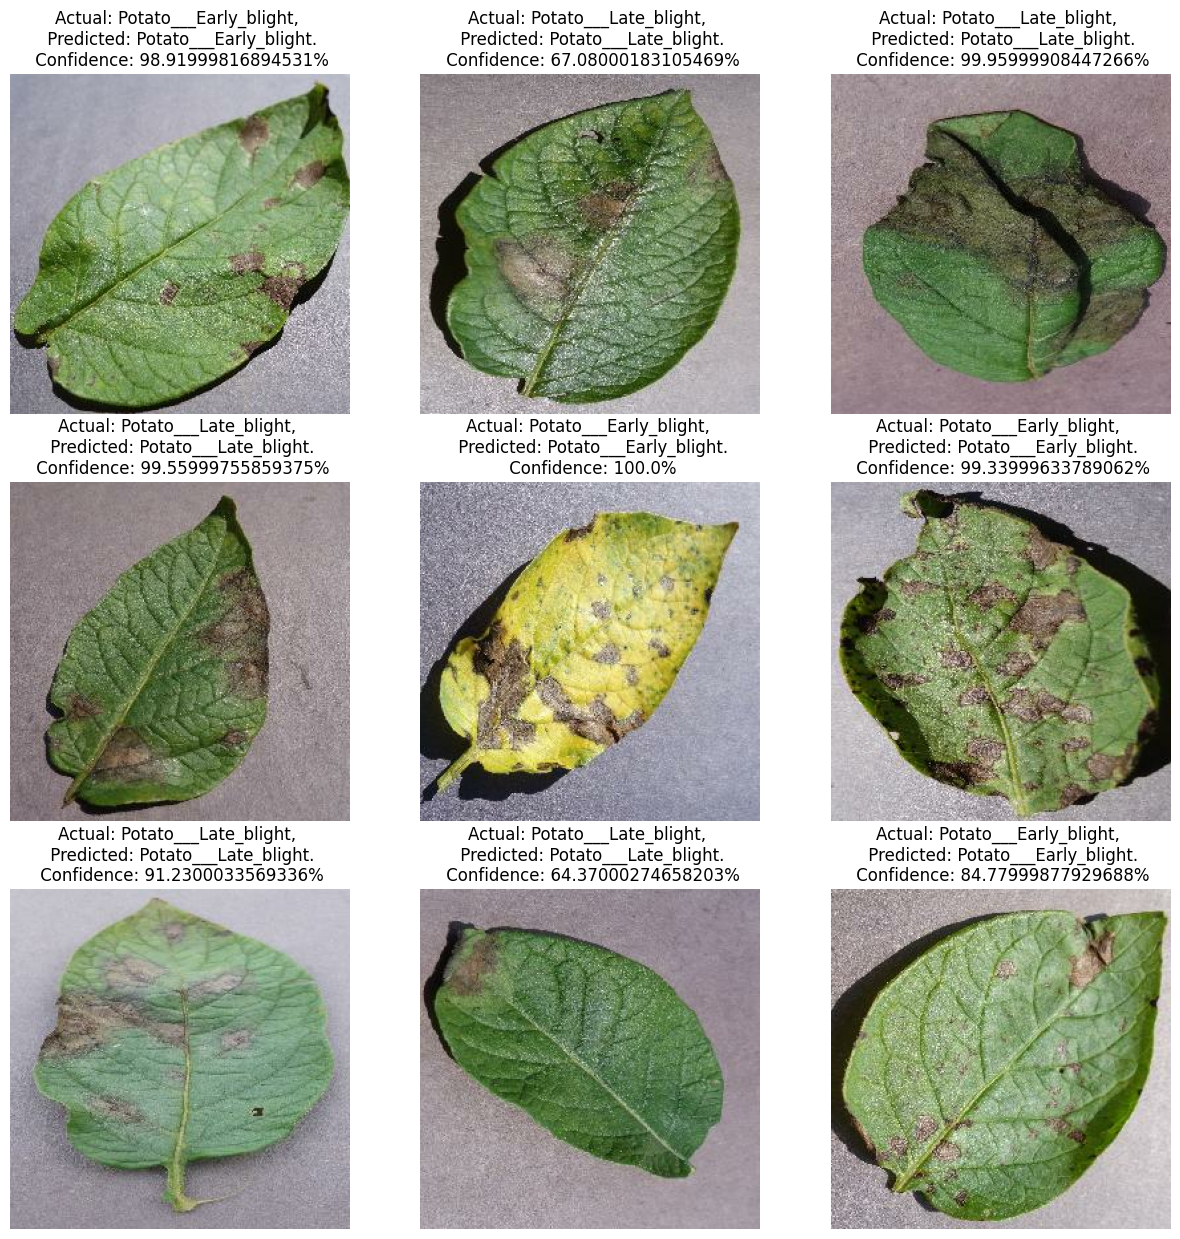

In [84]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
  for i in range(9):
    ax= plt.subplot(3, 3, i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    predicted_class, confidence = predict(model2, images[i].numpy())
    actual_class = class_names[labels[i]]
    plt.title(f"Actual: {actual_class}, \n Predicted: {predicted_class}.\n Confidence: {confidence}%")
    plt.axis("off")

In [87]:
model_version = 1
model2.save("image_classifier.keras")

In [89]:
from google.colab import files

files.download("image_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>